In [8]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [9]:
import os

print(os.listdir("/content"))

['.config', 'train.json.zip', 'archive.zip', 'train.json (1).zip', 'sample_data']


In [10]:
import zipfile

for filename in ["train.json.zip", "archive.zip"]:
    print(f"\nContents of {filename}:")

    with zipfile.ZipFile("/content/" + filename, "r") as z:
        for item in z.namelist()[:15]:
            print(item)


Contents of train.json.zip:
train.json
__MACOSX/
__MACOSX/._train.json

Contents of archive.zip:
PP_recipes.csv
PP_users.csv
RAW_interactions.csv
RAW_recipes.csv
ingr_map.pkl
interactions_test.csv
interactions_train.csv
interactions_validation.csv


In [11]:
import os
import zipfile

os.makedirs("/content/whatscooking", exist_ok=True)
os.makedirs("/content/foodcom", exist_ok=True)

with zipfile.ZipFile("/content/train.json.zip", "r") as zip_ref:
    zip_ref.extractall("/content/whatscooking")

with zipfile.ZipFile("/content/archive.zip", "r") as zip_ref:
    zip_ref.extractall("/content/foodcom")

print("Datasets extracted successfully!")

Datasets extracted successfully!


In [12]:
import json
import pandas as pd

# Load the What's Cooking dataset
with open("/content/whatscooking/train.json", "r") as file:
    cuisine_data = json.load(file)

cuisine_df = pd.DataFrame(cuisine_data)

# Load the Food.com dataset
food_df = pd.read_csv("/content/foodcom/RAW_recipes.csv")

print("What's Cooking Dataset")
print("Shape:", cuisine_df.shape)
display(cuisine_df.head())

print("\nFood.com Dataset")
print("Shape:", food_df.shape)
display(food_df.head())

What's Cooking Dataset
Shape: (39774, 3)


,id,cuisine,ingredients
0,10259,greek,"[romaine lettuce, black olives, grape tomatoes..."
1,25693,southern_us,"[plain flour, ground pepper, salt, tomatoes, g..."
2,20130,filipino,"[eggs, pepper, salt, mayonaise, cooking oil, g..."
3,22213,indian,"[water, vegetable oil, wheat, salt]"
4,13162,indian,"[black pepper, shallots, cornflour, cayenne pe..."



Food.com Dataset
Shape: (231637, 12)


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [13]:
print("WHAT'S COOKING DATASET")
print("\nColumns:")
print(cuisine_df.columns.tolist())

print("\nMissing values:")
print(cuisine_df.isnull().sum())

print("\nDuplicate rows:", cuisine_df.duplicated().sum())


print("\n\nFOOD.COM DATASET")
print("\nColumns:")
print(food_df.columns.tolist())

print("\nMissing values:")
print(food_df.isnull().sum())

print("\nDuplicate rows:", food_df.duplicated().sum())

WHAT'S COOKING DATASET

Columns:
['id', 'cuisine', 'ingredients']

Missing values:
id             0
cuisine        0
ingredients    0
dtype: int64


TypeError: unhashable type: 'list'

In [14]:
print("WHAT'S COOKING DATASET")

print("\nColumns:")
print(cuisine_df.columns.tolist())

print("\nMissing values:")
print(cuisine_df.isnull().sum())

print("\nDuplicate recipe IDs:", cuisine_df["id"].duplicated().sum())


print("\n\nFOOD.COM DATASET")

print("\nColumns:")
print(food_df.columns.tolist())

print("\nMissing values:")
print(food_df.isnull().sum())

print("\nDuplicate recipe IDs:", food_df["id"].duplicated().sum())

WHAT'S COOKING DATASET

Columns:
['id', 'cuisine', 'ingredients']

Missing values:
id             0
cuisine        0
ingredients    0
dtype: int64

Duplicate recipe IDs: 0


FOOD.COM DATASET

Columns:
['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'nutrition', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients']

Missing values:
name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

Duplicate recipe IDs: 0


In [15]:
# Remove duplicate recipe IDs
cuisine_df = cuisine_df.drop_duplicates(subset="id").copy()

# Remove rows with missing cuisine or ingredients
cuisine_df = cuisine_df.dropna(subset=["cuisine", "ingredients"])

# Remove recipes with empty ingredient lists
cuisine_df = cuisine_df[
    cuisine_df["ingredients"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    )
].copy()

# Combine ingredients into a single text string
cuisine_df["recipe_text"] = cuisine_df["ingredients"].apply(
    lambda ingredients: " ".join(ingredients)
)

print("Cleaning completed!")
print("Dataset shape:", cuisine_df.shape)

print("\nCuisine distribution:")
print(cuisine_df["cuisine"].value_counts())

print("\nSample recipe text:")
print(cuisine_df[["cuisine", "recipe_text"]].head())

Cleaning completed!
Dataset shape: (39774, 4)

Cuisine distribution:
cuisine
italian         7838
mexican         6438
southern_us     4320
indian          3003
chinese         2673
french          2646
cajun_creole    1546
thai            1539
japanese        1423
greek           1175
spanish          989
korean           830
vietnamese       825
moroccan         821
british          804
filipino         755
irish            667
jamaican         526
russian          489
brazilian        467
Name: count, dtype: int64

Sample recipe text:
       cuisine                                        recipe_text
0        greek  romaine lettuce black olives grape tomatoes ga...
1  southern_us  plain flour ground pepper salt tomatoes ground...
2     filipino  eggs pepper salt mayonaise cooking oil green c...
3       indian                     water vegetable oil wheat salt
4       indian  black pepper shallots cornflour cayenne pepper...


In [16]:
import ast

# Remove duplicate recipe IDs
food_df = food_df.drop_duplicates(subset="id").copy()

# Remove recipes with missing ingredients or nutrition
food_df = food_df.dropna(subset=["ingredients", "nutrition"])

# Convert nutrition lists from text into Python lists
food_df["nutrition"] = food_df["nutrition"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# Keep only rows with valid nutrition lists containing 7 values
food_df = food_df[
    food_df["nutrition"].apply(
        lambda x: isinstance(x, list) and len(x) == 7
    )
].copy()

print("Food.com cleaning completed!")
print("Dataset shape:", food_df.shape)

print("\nSample recipe names and nutrition:")
display(food_df[["name", "nutrition"]].head())

Food.com cleaning completed!
Dataset shape: (231637, 12)

Sample recipe names and nutrition:


,name,nutrition
0,arriba baked winter squash mexican style,"[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]"
1,a bit different breakfast pizza,"[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]"
2,all in the kitchen chili,"[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]"
3,alouette potatoes,"[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]"
4,amish tomato ketchup for canning,"[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]"


In [17]:
print("Total Food.com recipes:", len(food_df))
print("Total columns:", len(food_df.columns))

print("\nFirst 10 recipes:")
display(food_df[["name", "nutrition"]].head(10))

Total Food.com recipes: 231637
Total columns: 12

First 10 recipes:


,name,nutrition
0,arriba baked winter squash mexican style,"[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]"
1,a bit different breakfast pizza,"[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]"
2,all in the kitchen chili,"[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]"
3,alouette potatoes,"[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]"
4,amish tomato ketchup for canning,"[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]"
5,apple a day milk shake,"[160.2, 10.0, 55.0, 3.0, 9.0, 20.0, 7.0]"
6,aww marinated olives,"[380.7, 53.0, 7.0, 24.0, 6.0, 24.0, 6.0]"
7,backyard style barbecued ribs,"[1109.5, 83.0, 378.0, 275.0, 96.0, 86.0, 36.0]"
8,bananas 4 ice cream pie,"[4270.8, 254.0, 1306.0, 111.0, 127.0, 431.0, 2..."
9,beat this banana bread,"[2669.3, 160.0, 976.0, 107.0, 62.0, 310.0, 138.0]"


In [18]:
for _, row in food_df.head(10).iterrows():
    print("Recipe:", row["name"])
    print("Ingredients:", row["ingredients"])
    print("-" * 60)

Recipe: arriba   baked winter squash mexican style
Ingredients: ['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']
------------------------------------------------------------
Recipe: a bit different  breakfast pizza
Ingredients: ['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']
------------------------------------------------------------
Recipe: all in the kitchen  chili
Ingredients: ['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoes', 'kidney beans', 'water', 'chili powder', 'ground cumin', 'salt', 'lettuce', 'cheddar cheese']
------------------------------------------------------------
Recipe: alouette  potatoes
Ingredients: ['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', 'olive oil', 'red wine vinegar', 'salt', 'pepper', 'red bell pepper', 'yellow bell pepper']
--------------------------------------------------

In [19]:
print("Total What's Cooking recipes:", len(cuisine_df))
print("Total Food.com recipes:", len(food_df))

print("\nNumber of cuisines:")
print(cuisine_df["cuisine"].nunique())

print("\nCuisine names:")
print(sorted(cuisine_df["cuisine"].unique()))

Total What's Cooking recipes: 39774
Total Food.com recipes: 231637

Number of cuisines:
20

Cuisine names:
['brazilian', 'british', 'cajun_creole', 'chinese', 'filipino', 'french', 'greek', 'indian', 'irish', 'italian', 'jamaican', 'japanese', 'korean', 'mexican', 'moroccan', 'russian', 'southern_us', 'spanish', 'thai', 'vietnamese']


In [20]:
from sklearn.model_selection import train_test_split

# Input features and target labels
X = cuisine_df["recipe_text"]
y = cuisine_df["cuisine"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training recipes:", len(X_train))
print("Testing recipes:", len(X_test))
print("Total recipes:", len(X_train) + len(X_test))

Training recipes: 31819
Testing recipes: 7955
Total recipes: 39774


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert ingredient text into numerical features
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training feature shape: (31819, 5000)
Testing feature shape: (7955, 5000)


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create the model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict cuisines for test recipes
lr_predictions = lr_model.predict(X_test_tfidf)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression trained successfully!")
print("Test Accuracy:", round(lr_accuracy * 100, 2), "%")

Logistic Regression trained successfully!
Test Accuracy: 77.0 %


In [23]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

# Create the model
svm_model = LinearSVC(
    random_state=42,
    max_iter=3000
)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

# Predict cuisines for test recipes
svm_predictions = svm_model.predict(X_test_tfidf)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("Linear SVM trained successfully!")
print("Test Accuracy:", round(svm_accuracy * 100, 2), "%")

Linear SVM trained successfully!
Test Accuracy: 77.16 %


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
import pandas as pd

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, svm_predictions)
    ],
    "Weighted Precision": [
        precision_score(y_test, lr_predictions, average="weighted", zero_division=0),
        precision_score(y_test, svm_predictions, average="weighted", zero_division=0)
    ],
    "Weighted Recall": [
        recall_score(y_test, lr_predictions, average="weighted", zero_division=0),
        recall_score(y_test, svm_predictions, average="weighted", zero_division=0)
    ]
})

# Display results as percentages
results[["Accuracy", "Weighted Precision", "Weighted Recall"]] *= 100

display(results.round(2))

,Model,Accuracy,Weighted Precision,Weighted Recall
0,Logistic Regression,77.00,77.05,77.00
1,Linear SVM,77.16,76.77,77.16


In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

lr_parameters = {
    "C": [0.1, 1, 10]
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    lr_parameters,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train_tfidf, y_train)

print("Best Logistic Regression parameters:", lr_grid.best_params_)
print("Best cross-validation accuracy:", round(lr_grid.best_score_ * 100, 2), "%")

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Logistic Regression parameters: {'C': 10}
Best cross-validation accuracy: 76.71 %


In [26]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

svm_parameters = {
    "C": [0.1, 1, 10]
}

svm_grid = GridSearchCV(
    LinearSVC(max_iter=3000, random_state=42),
    svm_parameters,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train_tfidf, y_train)

print("Best Linear SVM parameters:", svm_grid.best_params_)
print("Best cross-validation accuracy:", round(svm_grid.best_score_ * 100, 2), "%")

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Linear SVM parameters: {'C': 1}
Best cross-validation accuracy: 77.0 %


In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
import pandas as pd

# Make predictions using the tuned models
lr_tuned_predictions = lr_grid.best_estimator_.predict(X_test_tfidf)
svm_tuned_predictions = svm_grid.best_estimator_.predict(X_test_tfidf)

# Compare the tuned models
tuned_results = pd.DataFrame({
    "Model": ["Tuned Logistic Regression", "Tuned Linear SVM"],
    "Accuracy (%)": [
        accuracy_score(y_test, lr_tuned_predictions) * 100,
        accuracy_score(y_test, svm_tuned_predictions) * 100
    ],
    "Weighted Precision (%)": [
        precision_score(y_test, lr_tuned_predictions, average="weighted", zero_division=0) * 100,
        precision_score(y_test, svm_tuned_predictions, average="weighted", zero_division=0) * 100
    ],
    "Weighted Recall (%)": [
        recall_score(y_test, lr_tuned_predictions, average="weighted", zero_division=0) * 100,
        recall_score(y_test, svm_tuned_predictions, average="weighted", zero_division=0) * 100
    ]
})

display(tuned_results.round(2))

,Model,Accuracy (%),Weighted Precision (%),Weighted Recall (%)
0,Tuned Logistic Regression,76.40,76.13,76.40
1,Tuned Linear SVM,77.16,76.77,77.16


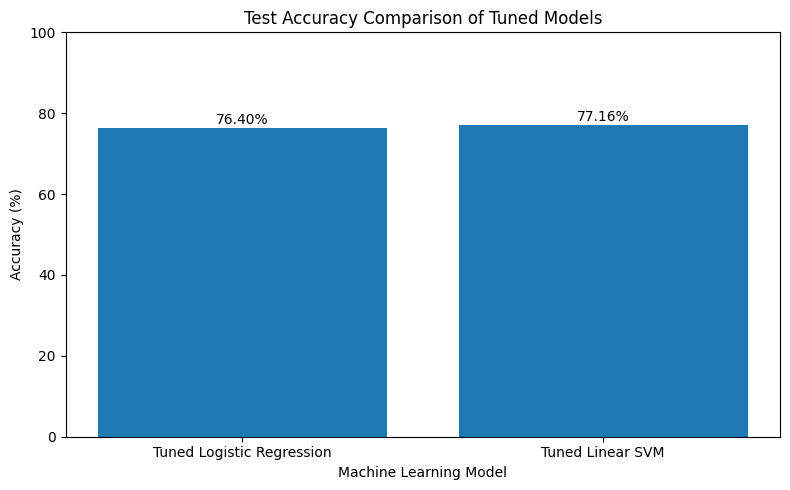

In [28]:
import matplotlib.pyplot as plt

models = tuned_results["Model"]
accuracies = tuned_results["Accuracy (%)"]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.title("Test Accuracy Comparison of Tuned Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

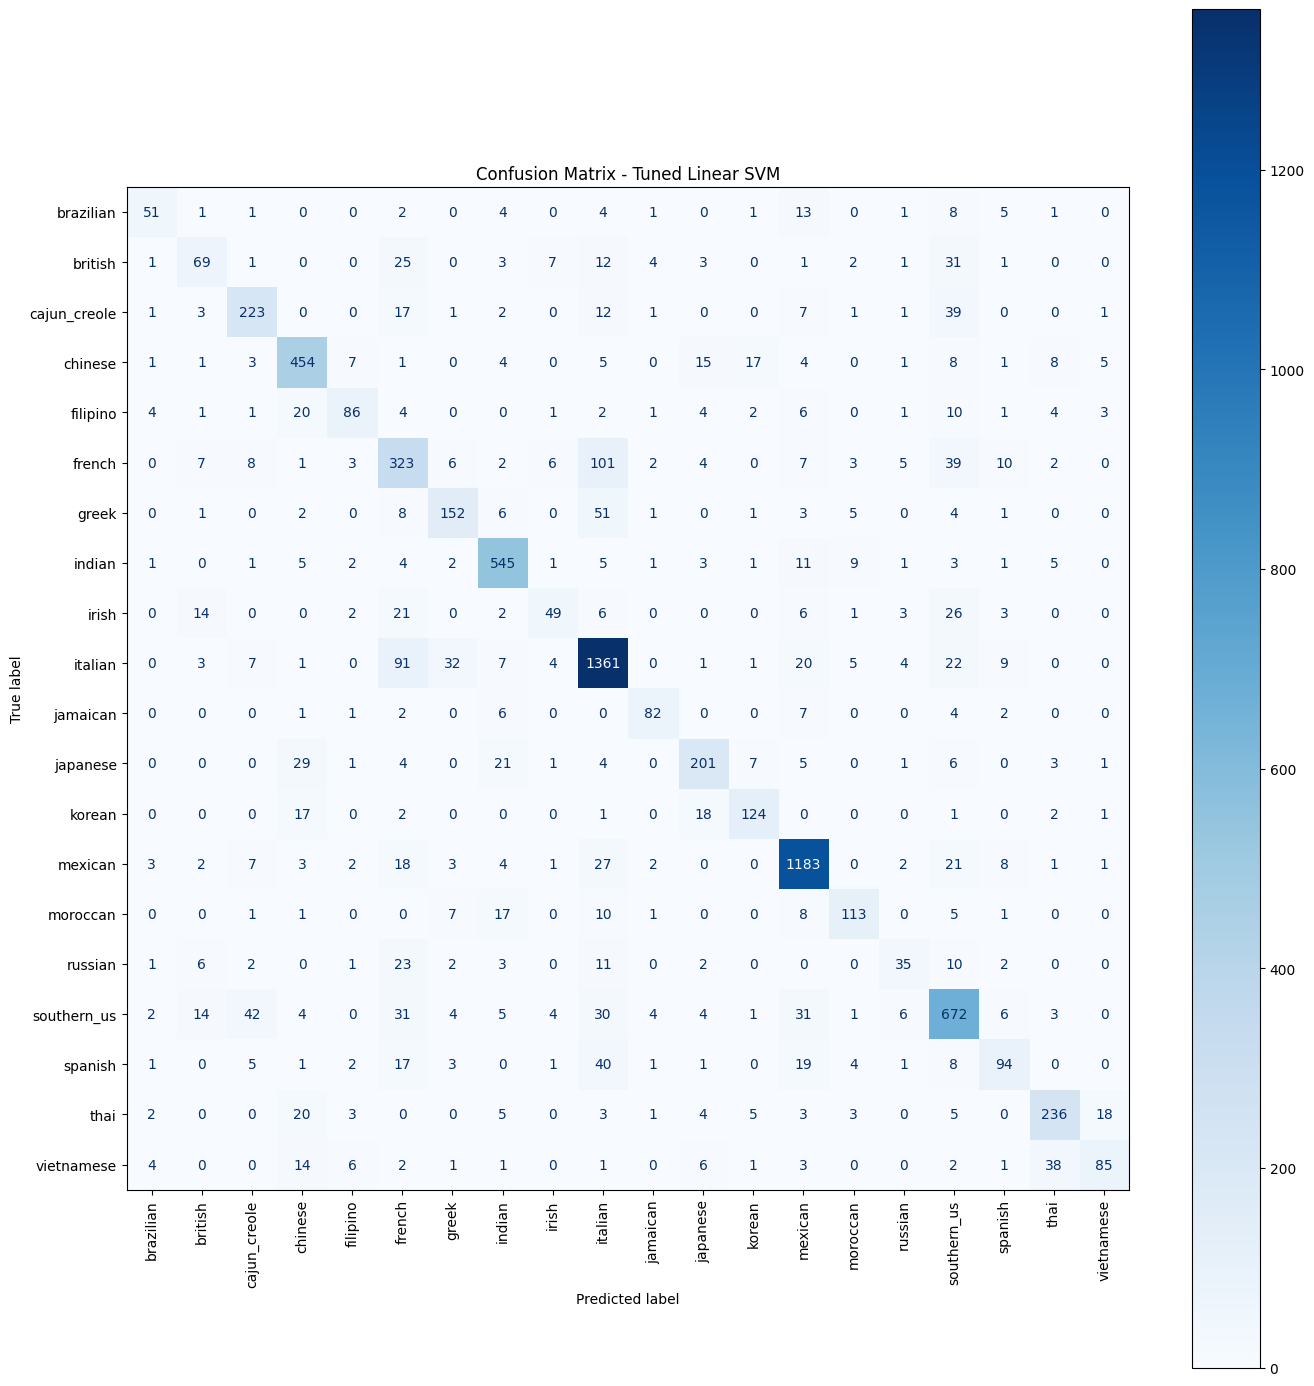

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Use predictions from the tuned Linear SVM
cm = confusion_matrix(
    y_test,
    svm_tuned_predictions,
    labels=svm_grid.best_estimator_.classes_
)

plt.figure(figsize=(14, 14))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_grid.best_estimator_.classes_
)

display.plot(
    xticks_rotation=90,
    cmap="Blues",
    values_format="d",
    ax=plt.gca()
)

plt.title("Confusion Matrix - Tuned Linear SVM")
plt.tight_layout()
plt.show()

In [30]:
# Nutrition list order in the Food.com dataset
nutrition_columns = [
    "calories",
    "total_fat_pdv",
    "sugar_pdv",
    "sodium_pdv",
    "protein_pdv",
    "saturated_fat_pdv",
    "carbohydrates_pdv"
]

# Convert the nutrition lists into separate columns
nutrition_df = pd.DataFrame(
    food_df["nutrition"].tolist(),
    columns=nutrition_columns,
    index=food_df.index
)

# Add nutritional columns to the Food.com dataset
food_df[nutrition_columns] = nutrition_df

print("Nutritional values extracted successfully!")
print("Dataset shape:", food_df.shape)

display(food_df[["name"] + nutrition_columns].head())

Nutritional values extracted successfully!
Dataset shape: (231637, 19)


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [31]:
from IPython.display import display as show_table

print("Nutritional columns:")
print(nutrition_columns)

print("\nSample recipes and their nutritional values:")
show_table(food_df[["name"] + nutrition_columns].head())

Nutritional columns:
['calories', 'total_fat_pdv', 'sugar_pdv', 'sodium_pdv', 'protein_pdv', 'saturated_fat_pdv', 'carbohydrates_pdv']

Sample recipes and their nutritional values:


,name,calories,total_fat_pdv,sugar_pdv,sodium_pdv,protein_pdv,saturated_fat_pdv,carbohydrates_pdv
0,arriba baked winter squash mexican style,51.5,0.0,13.0,0.0,2.0,0.0,4.0
1,a bit different breakfast pizza,173.4,18.0,0.0,17.0,22.0,35.0,1.0
2,all in the kitchen chili,269.8,22.0,32.0,48.0,39.0,27.0,5.0
3,alouette potatoes,368.1,17.0,10.0,2.0,14.0,8.0,20.0
4,amish tomato ketchup for canning,352.9,1.0,337.0,23.0,3.0,0.0,28.0


In [32]:
# Select a reproducible sample of 50,000 recipes
food_sample = food_df.sample(
    n=min(50000, len(food_df)),
    random_state=42
).copy()

# Combine ingredients into text for prediction
food_sample["recipe_text"] = food_sample["ingredients"].apply(
    lambda ingredients: " ".join(ingredients)
)

# Convert ingredients using the same TF-IDF vectorizer
food_sample_tfidf = tfidf.transform(food_sample["recipe_text"])

# Predict cuisines using the tuned Linear SVM
food_sample["predicted_cuisine"] = svm_grid.best_estimator_.predict(
    food_sample_tfidf
)

print("Cuisine prediction completed!")
print("Recipes analyzed:", len(food_sample))

print("\nPredicted cuisine counts:")
print(food_sample["predicted_cuisine"].value_counts())

print("\nSample predictions:")
show_table(
    food_sample[["name", "predicted_cuisine", "calories"]].head(10)
)

Cuisine prediction completed!
Recipes analyzed: 50000

Predicted cuisine counts:
predicted_cuisine
italian    50000
Name: count, dtype: int64

Sample predictions:


,name,predicted_cuisine,calories
59957,crab filled crescent snacks,italian,69.2
68281,curried bean salad,italian,256.0
71122,delicious steak with onion marinade,italian,58.6
163767,pork tenderloin with hoisin,italian,241.5
136941,mixed baby greens with oranges grapefruit and...,italian,212.8
31958,buttercream frosting,italian,238.7
62542,creamy cheesy scrambled eggs with basil,italian,303.5
52698,christmas hard candy,italian,3967.1
159716,pilgrim s cole slaw,italian,204.5
64215,creme de menthe chocolate vanilla drink,italian,204.2


In [33]:
import ast

# Convert Food.com ingredients from text into actual lists
food_sample["ingredients"] = food_sample["ingredients"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# Combine actual ingredient names into text
food_sample["recipe_text"] = food_sample["ingredients"].apply(
    lambda ingredients: " ".join(ingredients)
)

# Convert ingredients using the existing TF-IDF vectorizer
food_sample_tfidf = tfidf.transform(food_sample["recipe_text"])

# Predict cuisines again using the tuned Linear SVM
food_sample["predicted_cuisine"] = svm_grid.best_estimator_.predict(
    food_sample_tfidf
)

print("Updated predicted cuisine counts:")
print(food_sample["predicted_cuisine"].value_counts())

print("\nSample predictions:")
show_table(
    food_sample[["name", "predicted_cuisine", "calories"]].head(10)
)

Updated predicted cuisine counts:
predicted_cuisine
southern_us     12980
italian         11111
mexican          6207
french           4031
chinese          1839
british          1754
indian           1731
irish            1537
greek            1399
cajun_creole     1202
russian          1013
japanese          790
thai              786
moroccan          739
spanish           723
jamaican          669
filipino          479
brazilian         476
korean            297
vietnamese        237
Name: count, dtype: int64

Sample predictions:


,name,predicted_cuisine,calories
59957,crab filled crescent snacks,mexican,69.2
68281,curried bean salad,indian,256.0
71122,delicious steak with onion marinade,italian,58.6
163767,pork tenderloin with hoisin,chinese,241.5
136941,mixed baby greens with oranges grapefruit and...,italian,212.8
31958,buttercream frosting,southern_us,238.7
62542,creamy cheesy scrambled eggs with basil,italian,303.5
52698,christmas hard candy,moroccan,3967.1
159716,pilgrim s cole slaw,southern_us,204.5
64215,creme de menthe chocolate vanilla drink,italian,204.2


In [34]:
# Calculate average nutritional values for each predicted cuisine
nutrition_summary = food_sample.groupby("predicted_cuisine")[
    nutrition_columns
].mean()

# Round results for readability
nutrition_summary = nutrition_summary.round(2)

print("Average nutritional values by predicted cuisine:")
show_table(nutrition_summary)

# Save the results for your assignment
nutrition_summary.to_csv(
    "/content/nutrition_summary_by_cuisine.csv"
)

print("\nNutrition summary saved successfully!")

Average nutritional values by predicted cuisine:


,calories,total_fat_pdv,sugar_pdv,sodium_pdv,protein_pdv,saturated_fat_pdv,carbohydrates_pdv
predicted_cuisine,,,,,,,
brazilian,468.81,32.06,154.01,13.31,21.41,50.35,19.16
british,542.05,40.54,111.10,22.12,30.12,58.28,19.80
cajun_creole,493.71,40.05,51.44,46.38,43.90,47.63,13.54
chinese,414.70,31.52,59.58,42.24,44.58,26.34,10.95
filipino,485.84,33.10,115.43,57.85,41.42,43.89,16.97
french,505.05,42.65,92.68,26.82,34.53,64.22,14.86
greek,392.32,34.01,36.72,28.16,32.44,36.73,10.36
indian,386.60,27.64,51.07,24.01,32.16,29.89,13.13
irish,498.94,34.69,99.12,25.39,29.25,46.21,19.12



Nutrition summary saved successfully!


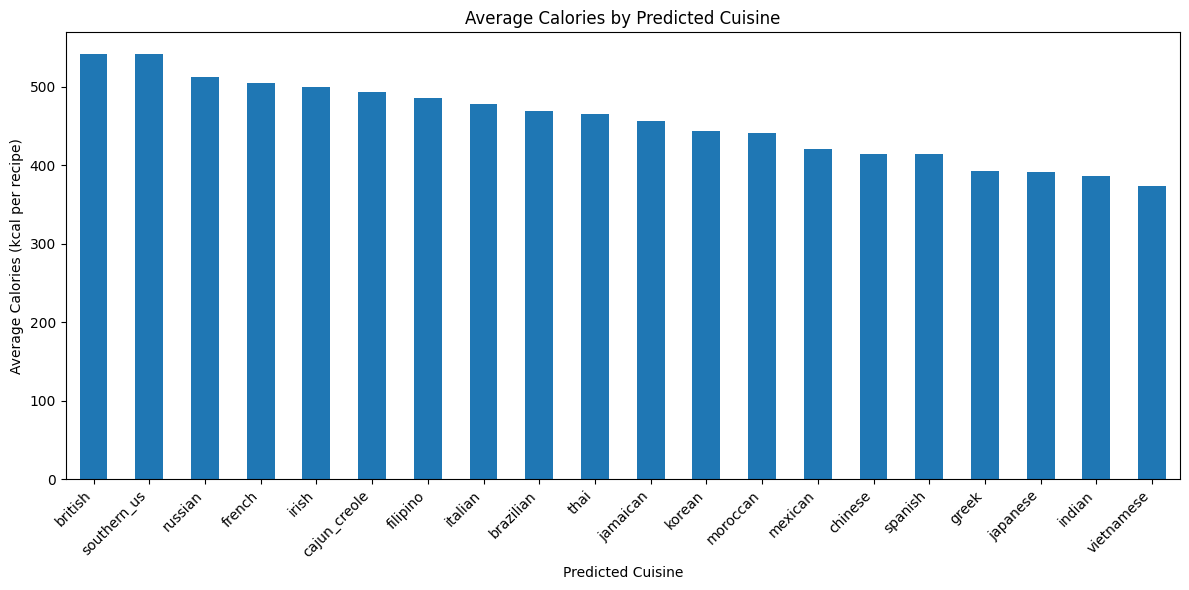

In [35]:
import matplotlib.pyplot as plt

# Sort cuisines by average calories
calorie_data = nutrition_summary["calories"].sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))

calorie_data.plot(kind="bar")

plt.title("Average Calories by Predicted Cuisine")
plt.xlabel("Predicted Cuisine")
plt.ylabel("Average Calories (kcal per recipe)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

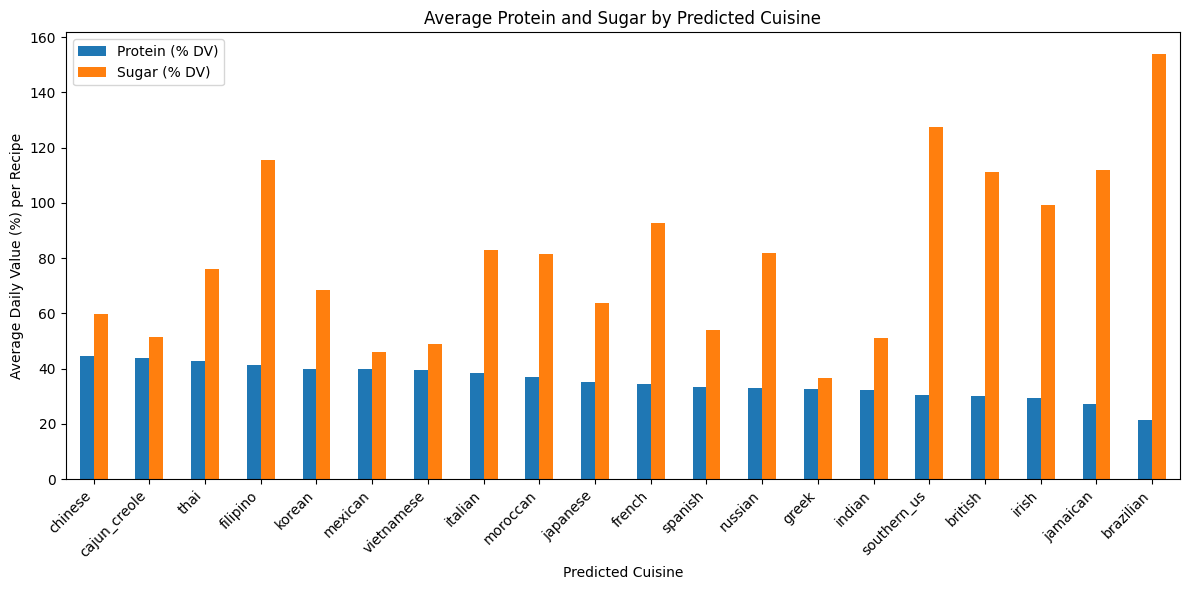

In [36]:
import matplotlib.pyplot as plt

# Select protein and sugar values
protein_sugar = nutrition_summary[
    ["protein_pdv", "sugar_pdv"]
].sort_values("protein_pdv", ascending=False)

# Create a grouped bar chart
protein_sugar.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Protein and Sugar by Predicted Cuisine")
plt.xlabel("Predicted Cuisine")
plt.ylabel("Average Daily Value (%) per Recipe")
plt.xticks(rotation=45, ha="right")
plt.legend(["Protein (% DV)", "Sugar (% DV)"])
plt.tight_layout()
plt.show()

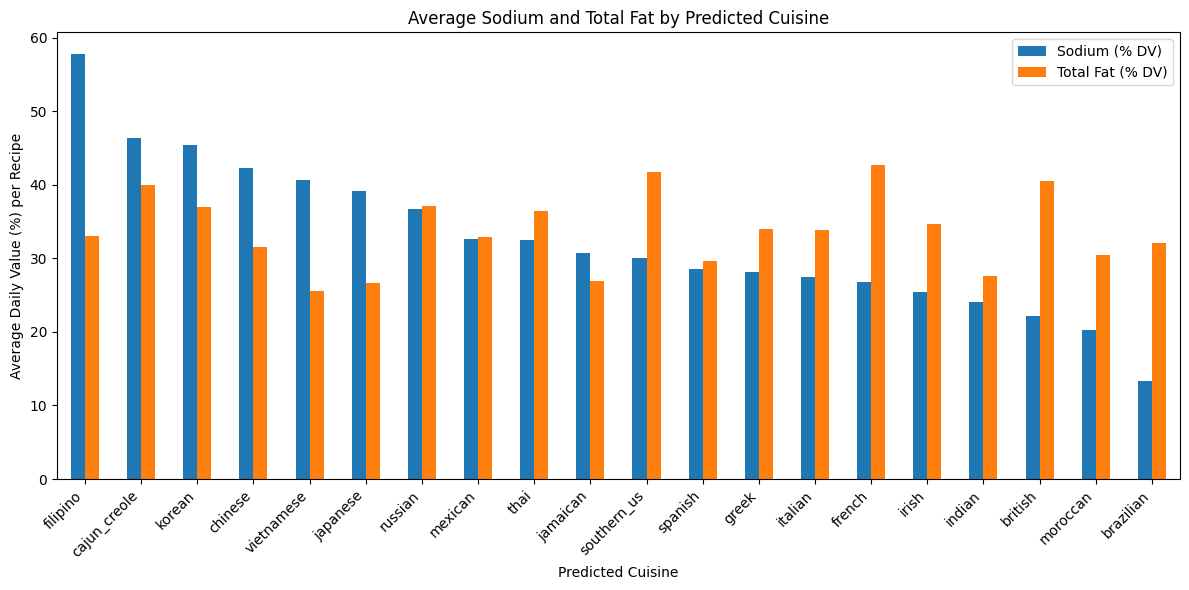

In [37]:
import matplotlib.pyplot as plt

# Select sodium and fat values
sodium_fat = nutrition_summary[
    ["sodium_pdv", "total_fat_pdv"]
].sort_values("sodium_pdv", ascending=False)

# Plot the comparison
sodium_fat.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Sodium and Total Fat by Predicted Cuisine")
plt.xlabel("Predicted Cuisine")
plt.ylabel("Average Daily Value (%) per Recipe")
plt.xticks(rotation=45, ha="right")
plt.legend(["Sodium (% DV)", "Total Fat (% DV)"])
plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import classification_report
import pandas as pd

# Generate per-cuisine evaluation metrics
report = classification_report(
    y_test,
    svm_tuned_predictions,
    output_dict=True,
    zero_division=0
)

# Convert the report into a table
report_df = pd.DataFrame(report).transpose()

# Keep only individual cuisine rows
cuisine_report = report_df.loc[
    svm_grid.best_estimator_.classes_,
    ["precision", "recall", "f1-score", "support"]
].copy()

# Convert metrics to percentages
cuisine_report[["precision", "recall", "f1-score"]] *= 100

# Sort by recall
cuisine_report = cuisine_report.sort_values(
    "recall",
    ascending=False
)

print("Per-cuisine performance of tuned Linear SVM:")
show_table(cuisine_report.round(2))

print("\nBest cuisine by recall:", cuisine_report.index[0])
print("Lowest cuisine by recall:", cuisine_report.index[-1])

Per-cuisine performance of tuned Linear SVM:


,precision,recall,f1-score,support
mexican,88.48,91.85,90.13,1288.0
indian,85.56,90.68,88.05,601.0
italian,80.72,86.80,83.65,1568.0
chinese,79.23,84.86,81.95,535.0
jamaican,80.39,78.10,79.23,105.0
southern_us,72.73,77.78,75.17,864.0
thai,77.89,76.62,77.25,308.0
korean,77.02,74.70,75.84,166.0
cajun_creole,73.84,72.17,73.00,309.0
japanese,75.56,70.77,73.09,284.0



Best cuisine by recall: mexican
Lowest cuisine by recall: russian


In [39]:
# Save model comparison results
tuned_results.to_csv(
    "/content/model_comparison.csv",
    index=False
)

# Save per-cuisine evaluation results
cuisine_report.to_csv(
    "/content/cuisine_classification_report.csv"
)

# Save nutritional analysis
nutrition_summary.to_csv(
    "/content/nutrition_summary_by_cuisine.csv"
)

print("All result files saved successfully!")

print("\nFiles created:")
print("1. model_comparison.csv")
print("2. cuisine_classification_report.csv")
print("3. nutrition_summary_by_cuisine.csv")

All result files saved successfully!

Files created:
1. model_comparison.csv
2. cuisine_classification_report.csv
3. nutrition_summary_by_cuisine.csv


In [40]:
from google.colab import files

files.download("/content/model_comparison.csv")
files.download("/content/cuisine_classification_report.csv")
files.download("/content/nutrition_summary_by_cuisine.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>